# AtliQ Grands: Hospitality Revenue & Occupancy Analysis (corrected and extended)

*Saurabh S · Oct 31, 2026*

> **Source:** This project is based on the **AtliQ Hotels Data Analysis project** from the **CodeBasics Python course**. The data is CodeBasics' fictional AtliQ Grands dataset.

This notebook rebuilds the course analysis end to end, with three goals:

1. **Fix two date issues** that silently dropped rows in the course notebook.
2. **Use weighted KPIs** (total booked ÷ total capacity) instead of averaging percentages.
3. **Add business KPIs** used in hospitality (RevPAR, realisation, cancellation and channel mix) and turn them into recommendations.

The CSV files aren't stored in this repository. To run this notebook, put them in a `datasets/` folder at the repository root (see `datasets/README.md`).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

DATA = Path("../datasets")
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
GOLD, NAVY, GREY = "#C9A227", "#1F2A44", "#9AA5B1"

def save(fig, name):
    fig.savefig(IMAGES / name, dpi=150, bbox_inches="tight")

def crore(x, _=None):
    return f"₹{x / 1e7:,.1f} Cr"    # 1 crore = 10 million rupees

## 1. Load the data

In [2]:
bookings = pd.read_csv(DATA / "fact_bookings.csv")
agg = pd.read_csv(DATA / "fact_aggregated_bookings.csv")
dates = pd.read_csv(DATA / "dim_date.csv")
hotels = pd.read_csv(DATA / "dim_hotels.csv")
rooms = pd.read_csv(DATA / "dim_rooms.csv")

for name, df in [("bookings", bookings), ("aggregated", agg), ("dates", dates), ("hotels", hotels), ("rooms", rooms)]:
    print(f"{name:<11} {df.shape}")

bookings    (134590, 12)
aggregated  (9200, 5)
dates       (92, 4)
hotels      (25, 4)
rooms       (4, 2)


In [3]:
print(hotels.groupby(["city", "category"]).size().unstack())
print()
print(rooms)

category   Business  Luxury
city                       
Bangalore         2       4
Delhi             2       3
Hyderabad         2       4
Mumbai            3       5

  room_id    room_class
0     RT1      Standard
1     RT2         Elite
2     RT3       Premium
3     RT4  Presidential


## 2. Data quality review

Before cleaning anything, I checked what was wrong with the data, and how each problem could change the results.

In [4]:
checks = {
    "Bookings with zero or negative guests": int((bookings["no_guests"] <= 0).sum()),
    "Bookings with missing guests": int(bookings["no_guests"].isnull().sum()),
    "Bookings with no rating": int(bookings["ratings_given"].isnull().sum()),
    "Aggregated rows with missing capacity": int(agg["capacity"].isnull().sum()),
    "Aggregated rows with bookings > capacity": int((agg["successful_bookings"] > agg["capacity"]).sum()),
}
for k, v in checks.items():
    print(f"{k:<45} {v:>7,}")

Bookings with zero or negative guests               9
Bookings with missing guests                        3
Bookings with no rating                        77,907
Aggregated rows with missing capacity               2
Aggregated rows with bookings > capacity            6


### 2.1 Two date problems in the course notebook

**Problem 1: two date formats that never match.** The aggregated file writes dates as `1-May-22`, but the date table writes `01-May-22`. Merging on these strings silently drops **every day from the 1st to the 9th** of each month.

In [5]:
course_merge = agg.merge(dates, left_on="check_in_date", right_on="date")
print(f"Rows kept by the course merge: {len(course_merge):,} of {len(agg):,} "
      f"({1 - len(course_merge) / len(agg):.0%} dropped)")

Rows kept by the course merge: 6,500 of 9,200 (29% dropped)


**Problem 2: day-first dates read as month-first.** Check-in dates mix two formats (`19-06-22` and `2/5/2022`, both day-first). The course notebook's `pd.to_datetime()` read `1/5/2022` (1 May) as 5 January, so those bookings fell out of the monthly revenue merge.

In [6]:
course_monthly_total = 389_940_912 + 377_191_229 + 408_375_641     # course notebook output (Jul + Jun + May)
print(f"Course notebook monthly revenue total: ₹{course_monthly_total:,}")

Course notebook monthly revenue total: ₹1,175,507,782


### 2.2 Cleaning steps

| Issue | Decision | Why |
| --- | --- | --- |
| Zero, negative or missing guests (12 rows) | Remove | A booking needs at least one guest |
| Revenue generated above mean + 3 std (5 rows, up to ₹2.86 Cr) | Remove | Clear data-entry outliers |
| Missing ratings (58% of bookings) | Keep as missing | Most guests don't rate, and filling would invent opinions |
| Missing capacity (2 rows) | Fill with that property and room's **own** capacity | Capacity is constant per property and room. The course used the overall median (25), which was wrong for both rows (actual 26 and 20) |
| Bookings > capacity (6 rows, e.g. 123 bookings for 26 rooms) | Remove | Impossible values |
| Date text in different formats | Parse explicitly with `format=` | Avoid silent mismatches |
| `"weekeday"` typo in the date table | Correct to `"weekday"` | Cleaner labels |

In [7]:
# bookings
bookings = bookings[bookings["no_guests"] > 0]                      # also removes the 3 missing values
limit = bookings["revenue_generated"].mean() + 3 * bookings["revenue_generated"].std()
bookings = bookings[bookings["revenue_generated"] <= limit].copy()
for col in ["booking_date", "check_in_date", "checkout_date"]:
    bookings[col] = pd.to_datetime(bookings[col], format="mixed", dayfirst=True)
bookings["nights"] = (bookings["checkout_date"] - bookings["check_in_date"]).dt.days
bookings["lead_days"] = (bookings["check_in_date"] - bookings["booking_date"]).dt.days

# aggregated bookings
own_capacity = agg.groupby(["property_id", "room_category"])["capacity"].transform(lambda s: s.fillna(s.mode()[0]))
print("Missing capacity filled with:", own_capacity[agg["capacity"].isnull()].tolist(), "(course used 25 for both)")
agg["capacity"] = own_capacity
agg = agg[agg["successful_bookings"] <= agg["capacity"]].copy()
agg["check_in_date"] = pd.to_datetime(agg["check_in_date"], format="%d-%b-%y")

# date dimension
dates["date"] = pd.to_datetime(dates["date"], format="%d-%b-%y")
dates["day_type"] = dates["day_type"].replace({"weekeday": "weekday"})
dates = dates.rename(columns={"mmm yy": "month", "week no": "week"})

print(f"Bookings after cleaning: {len(bookings):,} | aggregated rows: {len(agg):,}")
print("Check-in range:", bookings["check_in_date"].min().date(), "to", bookings["check_in_date"].max().date())

Missing capacity filled with: [26.0, 20.0] (course used 25 for both)
Bookings after cleaning: 134,573 | aggregated rows: 9,194
Check-in range: 2022-05-01 to 2022-07-31


## 3. Build the analysis tables

In [8]:
occ_df = (agg.merge(rooms, left_on="room_category", right_on="room_id")
             .merge(hotels, on="property_id")
             .merge(dates, left_on="check_in_date", right_on="date", validate="many_to_one"))
bk = (bookings.merge(rooms, left_on="room_category", right_on="room_id")
              .merge(hotels, on="property_id")
              .merge(dates, left_on="check_in_date", right_on="date", validate="many_to_one"))

print(f"Occupancy rows kept: {len(occ_df):,} of {len(agg):,}")
print(f"Booking rows kept:   {len(bk):,} of {len(bookings):,}")

Occupancy rows kept: 9,194 of 9,194
Booking rows kept:   134,573 of 134,573


In [9]:
def occupancy(df):
    """Weighted occupancy: total rooms booked / total rooms available."""
    return df["successful_bookings"].sum() / df["capacity"].sum() * 100

def occ_by(col):
    g = occ_df.groupby(col)[["successful_bookings", "capacity"]].sum()
    return (g["successful_bookings"] / g["capacity"] * 100).round(1)

print(f"Weighted occupancy: {occupancy(occ_df):.1f}%")
print(f"Average of row percentages (course method): {(occ_df['successful_bookings'] / occ_df['capacity'] * 100).mean():.1f}%")

Weighted occupancy: 57.9%
Average of row percentages (course method): 58.3%


## 4. Headline KPIs

| KPI | Definition |
| --- | --- |
| Revenue | Sum of `revenue_realized` (what the hotel actually collected) |
| Occupancy | Rooms booked ÷ rooms available |
| Realisation | Revenue realized ÷ revenue generated |
| ADR (Average Daily Rate) | Revenue ÷ number of bookings (the course project's simplified definition) |
| RevPAR | Revenue ÷ rooms available |
| DSRN | Bookings ÷ days in the period (daily sellable room nights used) |

In [10]:
revenue = bk["revenue_realized"].sum()
generated = bk["revenue_generated"].sum()
status = bk["booking_status"].value_counts(normalize=True) * 100
days = occ_df["check_in_date"].nunique()

kpis = pd.Series({
    "Bookings": f"{len(bk):,}",
    "Revenue realized": crore(revenue),
    "Occupancy": f"{occupancy(occ_df):.1f}%",
    "Realisation": f"{revenue / generated * 100:.1f}%",
    "Cancellation rate": f"{status['Cancelled']:.1f}%",
    "No-show rate": f"{status['No Show']:.1f}%",
    "ADR": f"₹{revenue / len(bk):,.0f}",
    "RevPAR": f"₹{revenue / occ_df['capacity'].sum():,.0f}",
    "DSRN": f"{len(bk) / days:,.0f}",
    "Average rating": f"{bk['ratings_given'].mean():.2f} ({bk['ratings_given'].notnull().mean():.0%} of bookings rated)",
})
print(kpis.to_string())

Bookings                                  134,573
Revenue realized                        ₹170.9 Cr
Occupancy                                   57.9%
Realisation                                 85.1%
Cancellation rate                           24.8%
No-show rate                                 5.0%
ADR                                       ₹12,696
RevPAR                                     ₹7,351
DSRN                                        1,463
Average rating       3.62 (42% of bookings rated)


In [11]:
corrected_total = bk["revenue_realized"].sum()
print(f"Corrected revenue total:  ₹{corrected_total:,}")
print(f"Course monthly total:     ₹{course_monthly_total:,}")
print(f"Missing from course view: {1 - course_monthly_total / corrected_total:.1%}")

Corrected revenue total:  ₹1,708,536,599
Course monthly total:     ₹1,175,507,782
Missing from course view: 31.2%


## 5. Insights

### 5.1 Weekends are full, weekdays are half empty

{'weekday': 51.3, 'weekend': 73.6}


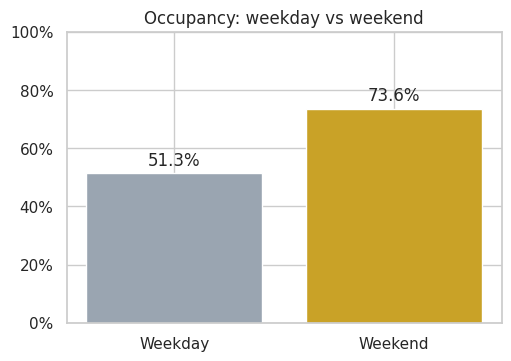

In [12]:
day_occ = occ_by("day_type")
print(day_occ.to_dict())

fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
bars = ax.bar(day_occ.index.str.title(), day_occ.values, color=[GREY, GOLD])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 100)
ax.set_title("Occupancy: weekday vs weekend")
save(fig, "01_weekday_weekend.png")
plt.show()

### 5.2 Mumbai earns the most, Delhi fills the best

           properties  bookings    revenue  rating  occupancy_%  revpar  revenue_share_%
city                                                                                    
Mumbai              8     43452  668569251    3.65         57.9  8908.0             39.1
Bangalore           6     32015  420383550    3.41         55.8  7334.0             24.6
Hyderabad           6     34883  325179310    3.66         58.1  5414.0             19.0
Delhi               5     24223  294404488    3.78         60.5  7364.0             17.2


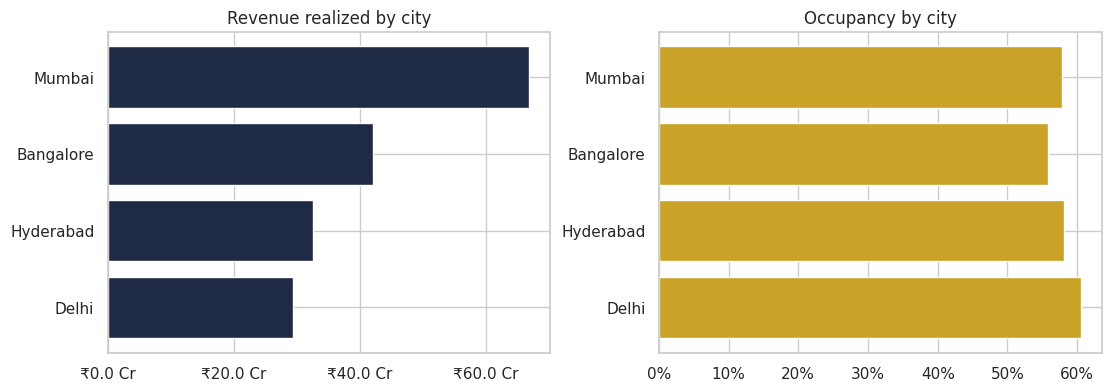

In [13]:
city = (bk.groupby("city")
          .agg(properties=("property_id", "nunique"), bookings=("booking_id", "size"),
               revenue=("revenue_realized", "sum"), rating=("ratings_given", "mean")))
city["occupancy_%"] = occ_by("city")
city["revpar"] = (city["revenue"] / occ_df.groupby("city")["capacity"].sum()).round(0)
city["revenue_share_%"] = (city["revenue"] / city["revenue"].sum() * 100).round(1)
city = city.sort_values("revenue", ascending=False)
print(city.round(2).to_string())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axs[0].barh(city.index[::-1], city["revenue"][::-1], color=NAVY)
axs[0].xaxis.set_major_locator(mtick.MaxNLocator(4))
axs[0].xaxis.set_major_formatter(mtick.FuncFormatter(crore))
axs[0].set_title("Revenue realized by city")
axs[1].barh(city.index[::-1], city["occupancy_%"][::-1], color=GOLD)
axs[1].xaxis.set_major_formatter(mtick.PercentFormatter())
axs[1].set_title("Occupancy by city")
save(fig, "02_city_revenue_occupancy.png")
plt.show()

### 5.3 Guest ratings move almost perfectly with occupancy

Correlation between average rating and occupancy across 25 properties: r = 0.998

Top 3 properties by revenue:
 property_id property_name   city   revenue  rating  occupancy_%
       16559 Atliq Exotica Mumbai 118419858    4.32        65.92
       17563  Atliq Palace Mumbai 101511080    4.29        66.23
       17559 Atliq Exotica Mumbai  93992150    4.32        66.10

Lowest 3 by rating:
 property_id property_name      city  revenue  rating  occupancy_%
       17564 Atliq Seasons    Mumbai 66086735    2.30        44.62
       18559 Atliq Exotica Hyderabad 47823120    2.33        44.63
       19558  Atliq Grands Bangalore 54494340    2.36        44.37

               properties  avg_rating  avg_occupancy
tier                                                
Low (< 2.75)            4        2.34          44.61
Mid                     9        3.05          53.44
High (> 3.75)          12        4.28          65.97


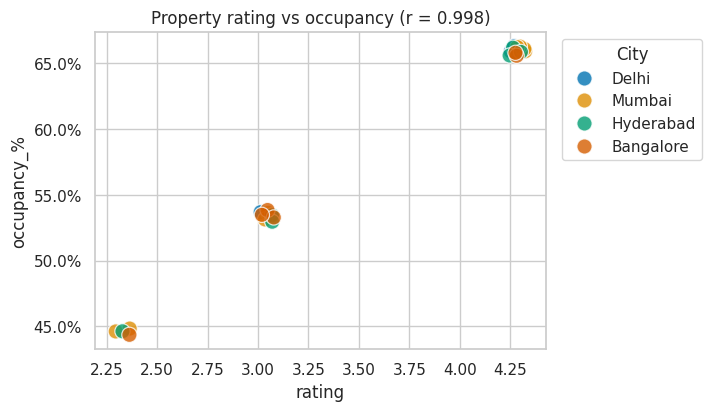

In [14]:
prop = (bk.groupby(["property_id", "property_name", "city"])
          .agg(revenue=("revenue_realized", "sum"), rating=("ratings_given", "mean"))
          .reset_index())
prop_occ = occ_df.groupby("property_id")[["successful_bookings", "capacity"]].sum()
prop["occupancy_%"] = prop["property_id"].map(prop_occ["successful_bookings"] / prop_occ["capacity"] * 100)
r = prop["rating"].corr(prop["occupancy_%"])
print(f"Correlation between average rating and occupancy across 25 properties: r = {r:.3f}")

cols = ["property_id", "property_name", "city", "revenue", "rating", "occupancy_%"]
print("\nTop 3 properties by revenue:")
print(prop.nlargest(3, "revenue")[cols].round(2).to_string(index=False))
print("\nLowest 3 by rating:")
print(prop.nsmallest(3, "rating")[cols].round(2).to_string(index=False))

prop["tier"] = pd.cut(prop["rating"], bins=[0, 2.75, 3.75, 5], labels=["Low (< 2.75)", "Mid", "High (> 3.75)"])
print()
print(prop.groupby("tier", observed=True).agg(properties=("property_id", "size"),
                                              avg_rating=("rating", "mean"),
                                              avg_occupancy=("occupancy_%", "mean")).round(2))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sns.scatterplot(data=prop, x="rating", y="occupancy_%", hue="city", s=120, alpha=0.8, ax=ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f"Property rating vs occupancy (r = {r:.3f})")
ax.legend(title="City", bbox_to_anchor=(1.02, 1), loc="upper left")
save(fig, "03_rating_vs_occupancy.png")
plt.show()

### 5.4 Cancellations: the biggest revenue leak

                revenue_generated  revenue_realized  kept_%
booking_status                                             
Cancelled               497914760         199165904    40.0
Checked Out            1408917655        1408917655   100.0
No Show                 100453040         100453040   100.0

Revenue generated but not realized: ₹29.9 Cr (14.9% of booked value)


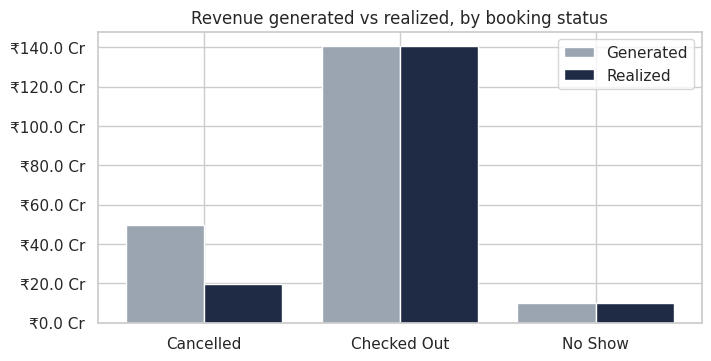

In [15]:
by_status = bk.groupby("booking_status")[["revenue_generated", "revenue_realized"]].sum()
by_status["kept_%"] = (by_status["revenue_realized"] / by_status["revenue_generated"] * 100).round(1)
print(by_status.to_string())
leak = generated - revenue
print(f"\nRevenue generated but not realized: {crore(leak)} ({leak / generated:.1%} of booked value)")

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
x = np.arange(len(by_status))
ax.bar(x - 0.2, by_status["revenue_generated"], 0.4, label="Generated", color=GREY)
ax.bar(x + 0.2, by_status["revenue_realized"], 0.4, label="Realized", color=NAVY)
ax.set_xticks(x, by_status.index)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(crore))
ax.set_title("Revenue generated vs realized, by booking status")
ax.legend()
save(fig, "04_revenue_leakage.png")
plt.show()

### 5.5 Booking channels: only 15% direct

                  bookings    revenue  cancel_rate  rating  share_%
booking_platform                                                   
others               55061  699306762        24.87    3.62     40.9
makeyourtrip         26896  340814104        24.99    3.62     20.0
logtrip              14753  187494028        24.31    3.62     11.0
direct online        13374  168948637        25.00    3.61      9.9
tripster              9630  123066801        24.99    3.62      7.2
journey               8106  102531334        24.78    3.63      6.0
direct offline        6753   86374933        24.49    3.62      5.0

Direct bookings: 14.9% | cancellation rates range 24.3% to 25.0%


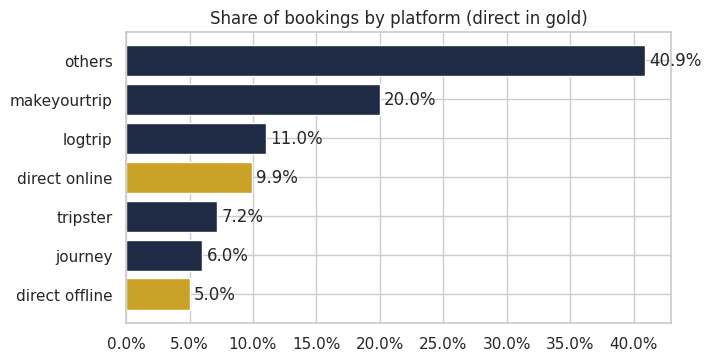

In [16]:
plat = (bk.groupby("booking_platform")
          .agg(bookings=("booking_id", "size"), revenue=("revenue_realized", "sum"),
               cancel_rate=("booking_status", lambda s: (s == "Cancelled").mean() * 100),
               rating=("ratings_given", "mean"))
          .sort_values("bookings", ascending=False))
plat["share_%"] = (plat["bookings"] / plat["bookings"].sum() * 100).round(1)
print(plat.round(2).to_string())
direct = plat.loc[["direct online", "direct offline"], "share_%"].sum()
print(f"\nDirect bookings: {direct:.1f}% | cancellation rates range "
      f"{plat['cancel_rate'].min():.1f}% to {plat['cancel_rate'].max():.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
colours = [GOLD if p.startswith("direct") else NAVY for p in plat.index]
bars = ax.barh(plat.index[::-1], plat["share_%"][::-1], color=colours[::-1])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Share of bookings by platform (direct in gold)")
save(fig, "05_platform_mix.png")
plt.show()

### 5.6 Room classes, categories and months

In [17]:
room = bk.groupby("room_class")["revenue_realized"].sum().to_frame("revenue")
room["occupancy_%"] = occ_by("room_class")
room["revenue_share_%"] = (room["revenue"] / room["revenue"].sum() * 100).round(1)
print(room.sort_values("revenue", ascending=False).to_string())

cat = bk.groupby("category")["revenue_realized"].sum().to_frame("revenue")
cat["occupancy_%"] = occ_by("category")
cat["properties"] = hotels["category"].value_counts()
print()
print(cat.to_string())

month_order = ["May 22", "Jun 22", "Jul 22"]
monthly = bk.groupby("month")["revenue_realized"].sum().reindex(month_order).to_frame("revenue")
monthly["occupancy_%"] = occ_by("month").reindex(month_order)
print()
print(monthly.to_string())

print(f"\nMedian booking lead time: {bk['lead_days'].median():.0f} days | average stay: {bk['nights'].mean():.2f} nights")

                revenue  occupancy_%  revenue_share_%
room_class                                           
Elite         560216304         57.6             32.8
Premium       462079944         57.6             27.0
Presidential  376693126         59.2             22.0
Standard      309547225         57.9             18.1

             revenue  occupancy_%  properties
category                                     
Business   655967037         58.2           9
Luxury    1052569562         57.7          16

          revenue  occupancy_%
month                         
May 22  581767396         58.5
Jun 22  553925855         57.6
Jul 22  572843348         57.4

Median booking lead time: 3 days | average stay: 2.37 nights


### 5.7 Appending the August data correctly

The course notebook appended `new_data_august.csv` directly. It has an `occ%` column (not `occ_pct`) and writes the month as `Aug-22` (not `Aug 22`), so the result gained a 15th column, and August rows had no `occ_pct`. Aligning the columns first fixes both.

In [18]:
august = pd.read_csv(DATA / "new_data_august.csv")
august = august.rename(columns={"occ%": "occ_pct", "mmm yy": "month", "week no": "week"})
august["month"] = august["month"].str.replace("-", " ")
august["check_in_date"] = pd.to_datetime(august["check_in_date"], format="%d-%b-%y")
august["day_type"] = august["day_type"].replace({"weekeday": "weekday"})

occ_df["occ_pct"] = (occ_df["successful_bookings"] / occ_df["capacity"] * 100).round(2)
cols = ["property_id", "property_name", "category", "city", "room_category", "room_class",
        "check_in_date", "month", "week", "day_type", "successful_bookings", "capacity", "occ_pct"]
latest = pd.concat([occ_df[cols], august[cols]], ignore_index=True)
print(latest.shape, "| months:", latest["month"].unique().tolist())

(9201, 13) | months: ['May 22', 'Jun 22', 'Jul 22', 'Aug 22']


## 6. Summary

1. **Weekdays are the opportunity.** Occupancy is 73.6% at weekends but 51.3% on weekdays.
2. **Mumbai drives revenue** (39% of the total), but **Delhi has the best occupancy (60.5%) and ratings (3.78)** from only 5 properties.
3. **Ratings and occupancy move together almost perfectly** across properties (r = 0.998). They fall into three clear tiers: properties rated around 2.3 run at about 45% occupancy, while those rated around 4.3 run at about 66%.
4. **Cancellations are the biggest leak.** A quarter of bookings are cancelled, and only 40% of their value is kept, so about ₹29.9 Cr of booked value is never realized.
5. **Only 15% of bookings come direct.** Cancellation rates are about 25% on every platform, so channel choice isn't driving cancellations.
6. **The course notebook understated total revenue by 31%** in its monthly view, and its occupancy views missed days 1–9 of every month, because of date-format mismatches.

See the README for recommendations.